# Домашня робота на тему "Основи машинного навчання. Базова регресія"

Цей ноутбук містить завдання для домашньої роботи з використанням датасету California Housing.

## Імпорт бібліотек та завантаження даних

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree._criterion import MAE

# Завантаження датасету California Housing
housing = fetch_california_housing(as_frame=True)

# Перетворення на DataFrame для зручності
df = housing.frame

# Випадковий вибір 5000 рядків з фіксованим seed для відтворюваності
df = df.sample(n=5000, random_state=42)

# Вивід перших 5 рядків датасету
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000


## Завдання 1: Лінійна регресія на одній ознаці MedInc

**Умова:**
1. Завантажити датасет California Housing.
2. Взяти тільки одну ознаку MedInc і випадкові 5000 рядків.
3. Розділити дані на навчальну і тестову вибірки (80/20) з random_state=42.
4. Навчити модель LinearRegression.
5. Обчислити коефіцієнт детермінації R² на тестовій вибірці.
6. Вивести результат у таблиці.

In [16]:
# Вибір ознаки MedInc
X = df[["MedInc"]]
y = df["MedHouseVal"]

# Розділення на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Навчання моделі
model = LinearRegression()
model.fit(X_train, y_train)

# Передбачення та R²
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

# Таблиця результатів
results = pd.DataFrame({
    "Feature": ["MedInc"],
    "R^2": [r2]
})
display(results)

,Feature,R^2
0,MedInc,0.496119


## Завдання 2: Порівняння якості на одній та двох ознаках

**Умова:**
1. Використовувати датасет California Housing (випадкові 5000 рядків).
2. Побудувати дві моделі:
   - тільки з ознакою MedInc;
   - з ознаками MedInc і AveRooms.
3. Розділити дані на навчальну і тестову вибірки (80/20) з random_state=42.
4. Обчислити R² на тестовій вибірці.
5. Вивести результати в таблиці.

In [21]:
# Підготовка даних
X = df[["MedInc", "AveRooms"]]
y = df["MedHouseVal"]

# Розділення (використовуємо ті ж самі train/test розбиття для обох моделей)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Модель на одній ознаці
model1 = LinearRegression()
model1.fit(X_train[["MedInc"]], y_train)
y_pred1= model1.predict(X_test[["MedInc"]])
r2_1 = r2_score(y_test, y_pred1)

# Модель на двох ознаках
model2 = LinearRegression()
model2.fit(X_train, y_train)
y_pred2= model2.predict(X_test)
r2_2 = r2_score(y_test, y_pred2)

# Таблиця результатів
results = pd.DataFrame({
    "Feature": ["MedInc", "MedInc + AveRooms"],
    "R^2": [r2_1, r2_2]
})
display(results.round(4))

,Feature,R^2
0,MedInc,0.4961
1,MedInc + AveRooms,0.5037


## Завдання 3: Обчислення метрик помилки для моделі з двома ознаками

**Умова:**
1. Використовувати датасет California Housing (випадкові 5000 рядків).
2. Розділити дані на навчальну і тестову вибірки (80/20) з random_state=42.
3. Побудувати модель лінійної регресії на ознаках MedInc і AveRooms.
4. На тестовій вибірці порахувати:
   - MAE,
   - MSE,
   - RMSE,
   - R².
5. Оформити результати в таблиці.

In [25]:
# Використовуємо вже підготовлені X_train_two, X_test_two, y_train, y_test із завдання 2
# Переконаємось, що вони відповідають ознакам MedInc та AveRooms
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Модель вже навчена (model2), але для чистоти обчислимо знову
model2 = LinearRegression()
model2.fit(X_train, y_train)
y_pred2= model2.predict(X_test)
r2_2 = r2_score(y_test, y_pred2)

# Обчислення метрик
mae = mean_absolute_error(y_test, y_pred2)
mse = mean_squared_error(y_test, y_pred2)
rmse = np.sqrt(mse)


# Таблиця результатів
results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R^2"],
    "Value": [mae, mse, rmse, r2_2]
})
display(results)

,Metric,Value
0,MAE,0.613654
1,MSE,0.670310
2,RMSE,0.818724
3,R^2,0.503710


## Завдання 4: Графік порівняння реальних і передбачених значень

**Умова:**
1. Використовувати датасет California Housing (випадкові 5000 рядків).
2. Розділити дані на навчальну і тестову вибірки (80/20) з random_state=42.
3. Побудувати модель лінійної регресії на ознаках MedInc і AveRooms.
4. Отримати передбачення на тестовій вибірці.
5. Побудувати scatter-графік: по осі X — y_test, по осі Y — y_pred.
6. Додати лінію y = x (ідеальні передбачення).
7. Підписати осі та зберегти графік у файл.

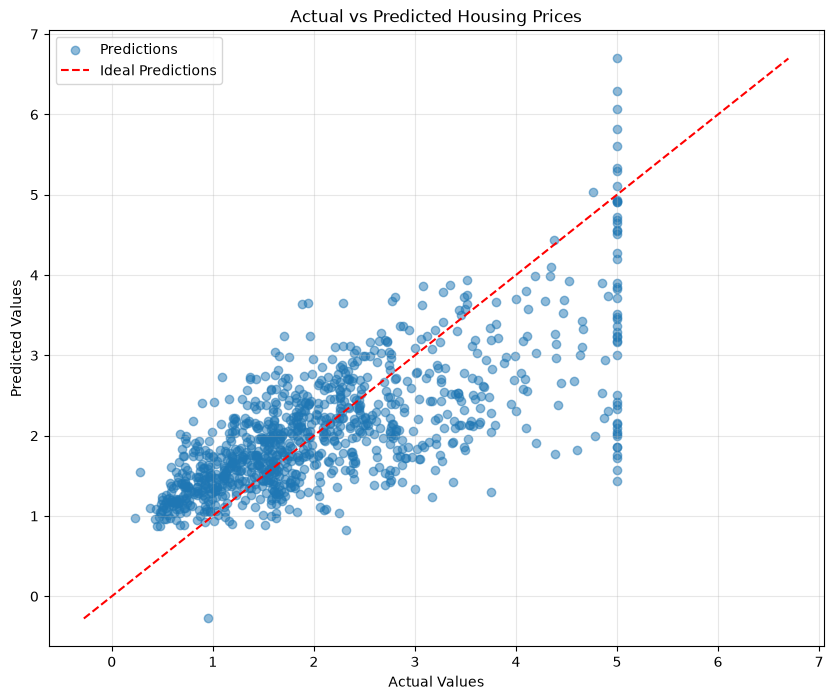

In [28]:
 # Використовуємо вже підготовлені дані та модель з попереднього завдання
# Побудова графіка
plt.figure(figsize=(10, 8))
plt.scatter(y_test, y_pred2, alpha=0.5, label="Predictions")
min_val = min(y_test.min(), y_pred2.min())
max_val = max(y_test.max(), y_pred2.max())
# Лінія y = x
plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linestyle="--", label="Ideal Predictions")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Housing Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("housing_predicions.png", dpi=2000, bbox_inches="tight")
plt.show()